In [1]:
import pandas as pd
import sqlite3

df = pd.read_csv("../data/student-mat.csv", sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
conn = sqlite3.connect("../data/students.db")
df.to_sql("students", conn, if_exists="replace", index=False)

query = """
SELECT studytime, ROUND(AVG(G3), 2) AS avg_final_grade, COUNT(*) AS students
FROM students
GROUP BY studytime
ORDER BY studytime
"""
pd.read_sql(query, conn)

,studytime,avg_final_grade,students
0,1,10.05,105
1,2,10.17,198
2,3,11.40,65
3,4,11.26,27


In [3]:
df.info()
print("Missing values:", df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

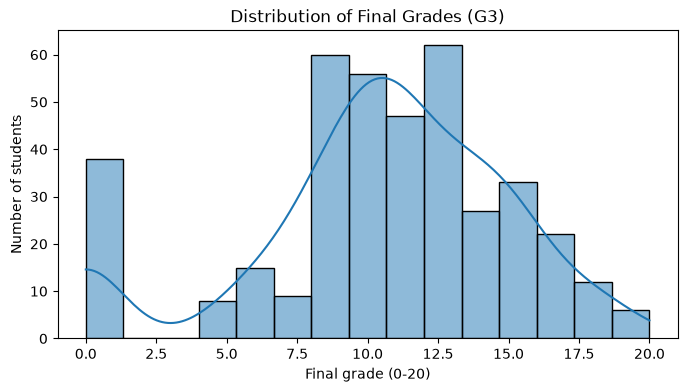

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(df["G3"], bins=15, kde=True)
plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final grade (0-20)")
plt.ylabel("Number of students")
plt.show()

**Finding:** Most students score 8-14, but about 38 students have a final grade of 0, forming a separate group (likely dropouts or students who did not take the final exam).

In [5]:
query = """
SELECT failures, ROUND(AVG(G3), 2) AS avg_final_grade, COUNT(*) AS students
FROM students
GROUP BY failures
ORDER BY failures
"""
pd.read_sql(query, conn)

,failures,avg_final_grade,students
0,0,11.25,312
1,1,8.12,50
2,2,6.24,17
3,3,5.69,16


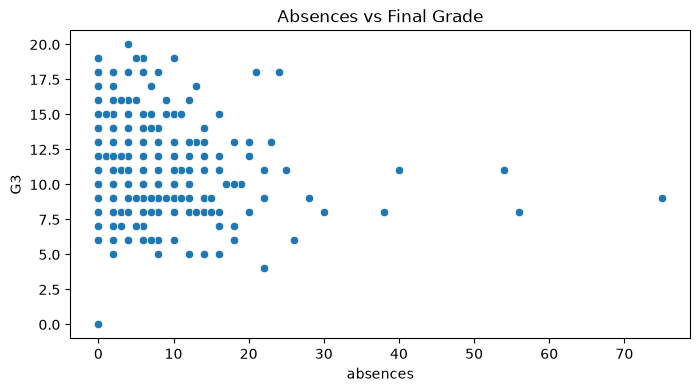

In [6]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="absences", y="G3")
plt.title("Absences vs Final Grade")
plt.show()

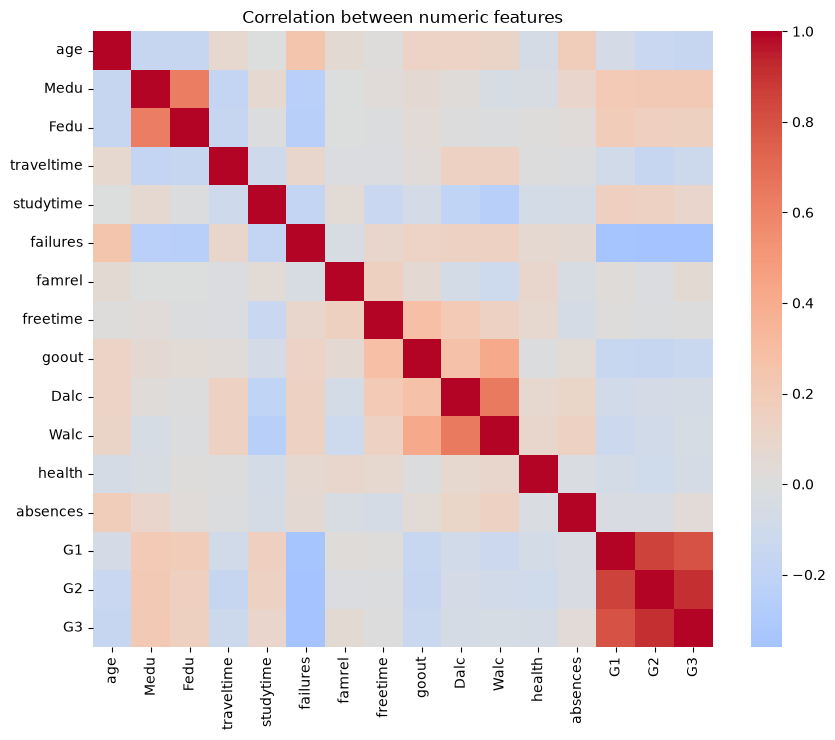

G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64

In [7]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation between numeric features")
plt.show()

corr["G3"].sort_values(ascending=False)

**Finding:** Absences alone show no clear relationship with the final grade. The grades G1 and G2 are the strongest predictors of G3.